# RetailIQ - Data Science Walkthrough

This notebook explains, step by step, what the RetailIQ backend does behind the scenes:

1. Load data in **M5 format** (wide sales table, calendar, prices)
2. Reshape it and run **exploratory data analysis**
3. Engineer **leakage-free features** for forecasting
4. Compare **five forecasting models** with **time-based splits**
5. Explain the best tree model with **SHAP**
6. Turn the forecast into **inventory recommendations**

> **Data notice:** the files in `data/sample/m5_synthetic` are **synthetic** (generated by `backend/app/services/sample_data.py`) in the exact M5 file format. They are *not* real Walmart data. To use the real M5 data, download it from Kaggle into `data/m5/` and change `DATA_DIR` below.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "backend"))   # reuse the app's own, tested modules

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
DATA_DIR = ROOT / "data" / "sample" / "m5_synthetic"
pd.set_option("display.width", 140)

## 1. Load the M5-format files
M5 stores sales in a **wide** table: one row per item × store, one column per day (`d_1`, `d_2`, ...).

In [2]:
sales_wide = pd.read_csv(DATA_DIR / "sales_train_synthetic.csv")
calendar = pd.read_csv(DATA_DIR / "calendar.csv", parse_dates=["date"])
prices = pd.read_csv(DATA_DIR / "sell_prices.csv")
names = pd.read_csv(DATA_DIR / "item_names.csv")
print(sales_wide.shape, calendar.shape, prices.shape)
sales_wide.iloc[:3, :10]

(300, 736) (730, 14) (31480, 4)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,5,7,15,10
1,FOODS_1_001_CA_2_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_2,CA,10,15,13,11
2,FOODS_1_001_CA_3_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_3,CA,12,28,20,8


## 2. Reshape: wide → long, and add revenue
`melt` turns the day columns into rows. Revenue = units × the weekly selling price (joined through the fiscal week id `wm_yr_wk`).

In [3]:
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
long = sales_wide.melt(id_vars=id_cols, var_name="d", value_name="units")
long = long.merge(calendar[["d", "date", "wm_yr_wk", "weekday", "month", "event_name_1", "event_type_1"]], on="d")
long = long.merge(prices, on=["store_id", "item_id", "wm_yr_wk"], how="left")
long["revenue"] = long.units * long.sell_price.fillna(0)
long = long.merge(names[["item_id", "item_name"]], on="item_id")
print(f"{len(long):,} rows; {(long.units == 0).mean():.1%} of store-item-days have zero sales")
long.head()

219,000 rows; 25.3% of store-item-days have zero sales


,id,item_id,dept_id,cat_id,store_id,state_id,d,units,date,wm_yr_wk,weekday,month,event_name_1,event_type_1,sell_price,revenue,item_name
0,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1,5,2024-11-01,12442,Friday,11,NaN,NaN,3.48,17.40,Whole Milk 1 gal
1,FOODS_1_001_CA_2_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_2,CA,d_1,10,2024-11-01,12442,Friday,11,NaN,NaN,3.48,34.80,Whole Milk 1 gal
2,FOODS_1_001_CA_3_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_3,CA,d_1,12,2024-11-01,12442,Friday,11,NaN,NaN,3.48,41.76,Whole Milk 1 gal
3,FOODS_1_001_CA_4_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_4,CA,d_1,7,2024-11-01,12442,Friday,11,NaN,NaN,3.48,24.36,Whole Milk 1 gal
4,FOODS_1_001_TX_1_evaluation,FOODS_1_001,FOODS_1,FOODS,TX_1,TX,d_1,23,2024-11-01,12442,Friday,11,NaN,NaN,3.48,80.04,Whole Milk 1 gal


## 3. Exploratory data analysis

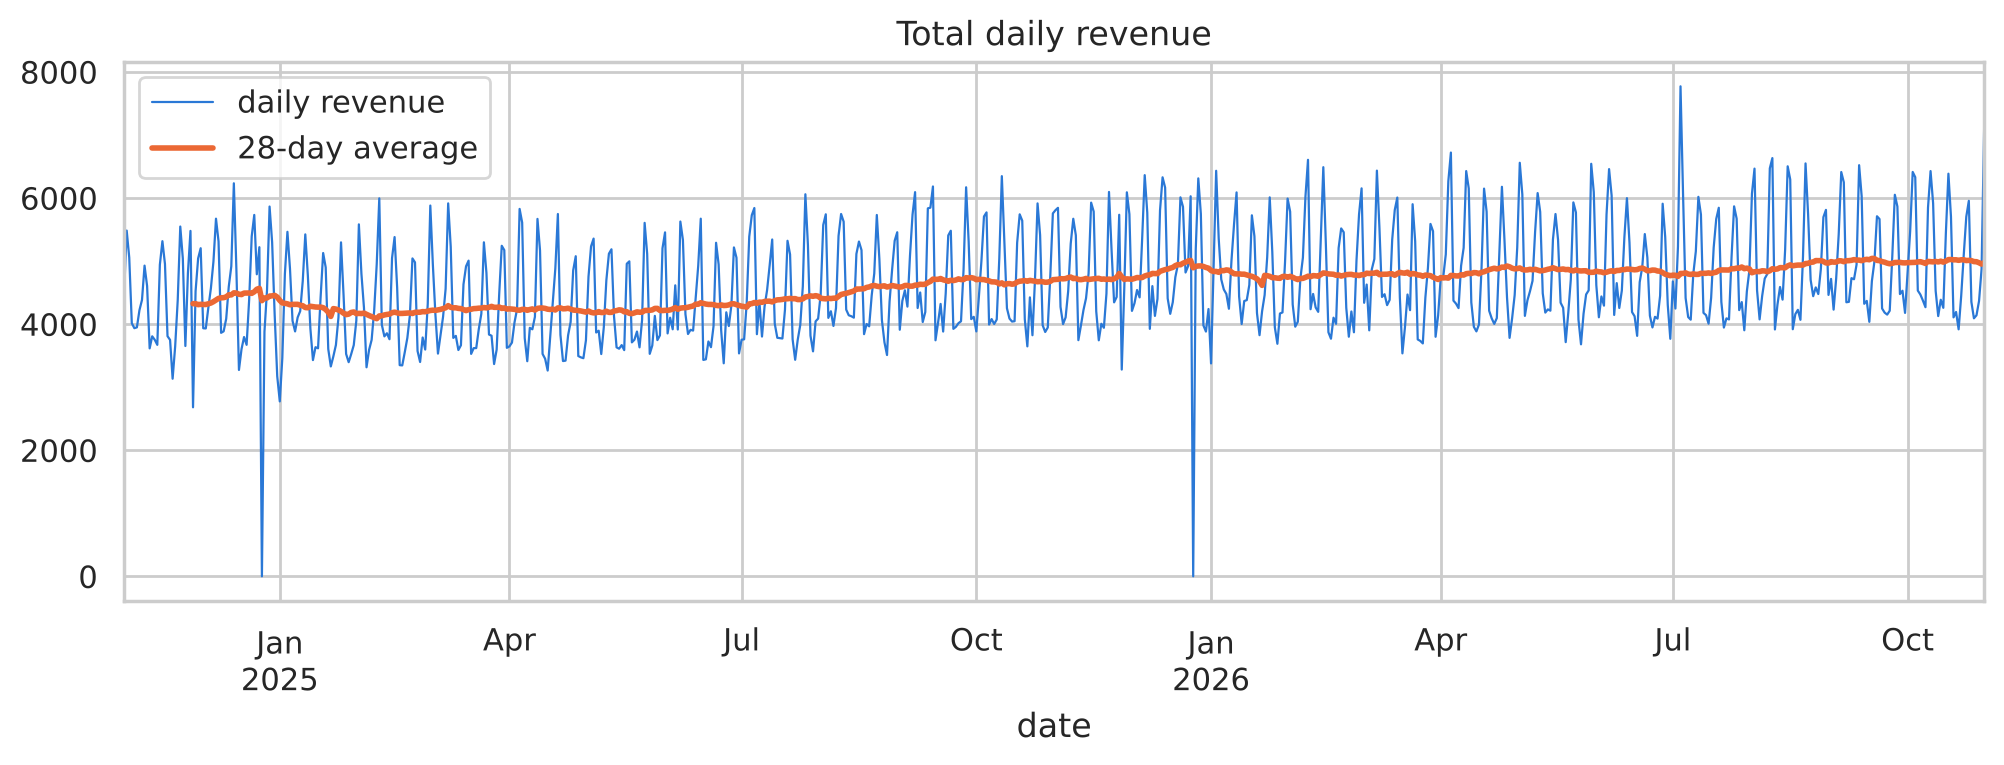

In [4]:
daily = long.groupby("date")[["units", "revenue"]].sum()
fig, ax = plt.subplots(figsize=(12, 3.5))
daily.revenue.plot(ax=ax, lw=0.8, color="#2a78d6", label="daily revenue")
daily.revenue.rolling(28).mean().plot(ax=ax, lw=2, color="#eb6834", label="28-day average")
ax.set_title("Total daily revenue"); ax.legend(); plt.show()

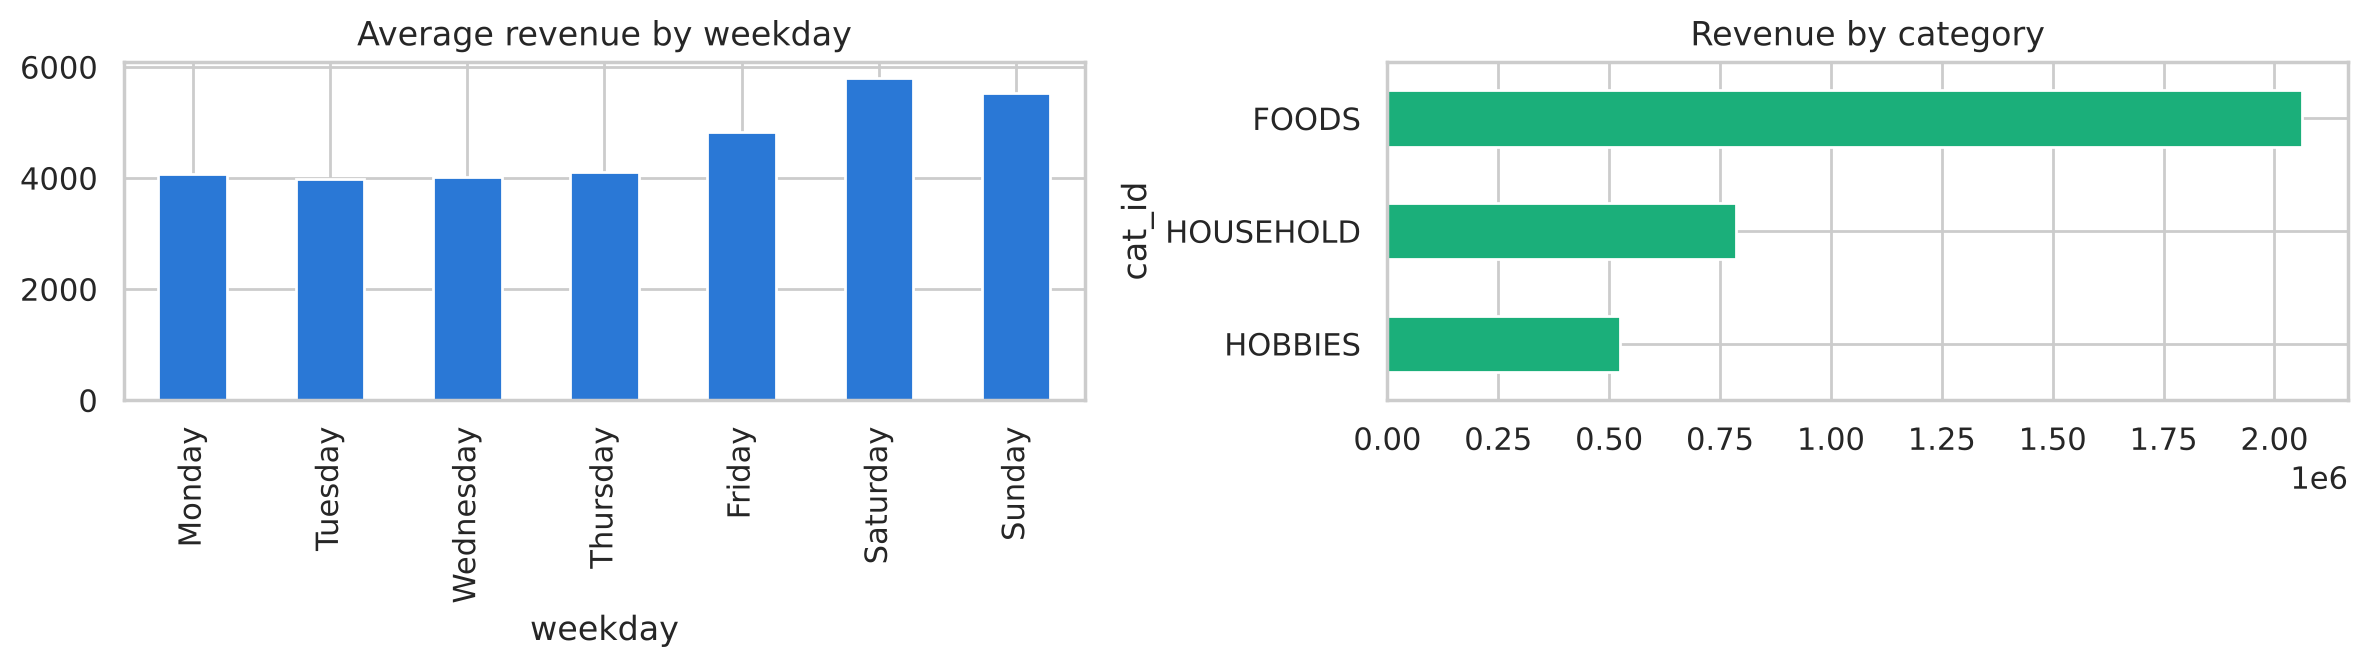

cat_id
HOBBIES      0.155
HOUSEHOLD    0.233
FOODS        0.612
Name: revenue, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
wd = long.groupby(["date", "weekday"]).revenue.sum().reset_index().groupby("weekday").revenue.mean().reindex(order)
wd.plot.bar(ax=axes[0], color="#2a78d6", title="Average revenue by weekday")
cat = long.groupby("cat_id").revenue.sum().sort_values()
cat.plot.barh(ax=axes[1], color="#1baf7a", title="Revenue by category")
plt.tight_layout(); plt.show()
print((cat / cat.sum()).round(3))

In [6]:
# Event effect: average units per store-item on event days vs normal days (association, not causation)
long["is_event"] = long.event_name_1.notna()
print(long.groupby("is_event").units.mean().rename({False: "normal day", True: "event day"}))
long[["units", "sell_price", "revenue"]].describe().T

is_event
normal day    3.532386
event day     3.520667
Name: units, dtype: float64


,count,mean,std,min,25%,50%,75%,max
units,219000.0,3.531904,4.982911,0.0,0.00,2.00,5.00,162.00
sell_price,216820.0,7.536605,5.435041,0.4,3.48,6.55,9.97,27.47
revenue,219000.0,15.402191,18.105415,0.0,0.00,9.97,22.14,333.48


## 4. Forecasting: features without leakage

For predicting day *t* we may only use sales **up to day t-1**. That is why every lag and rolling feature is computed on the series shifted by one day. Calendar, events and planned prices are known in advance, so they can be used for day *t*.

We reuse the exact functions from the app (`app.forecasting.features`).

In [7]:
from app.forecasting.features import _calendar_block, build_training_frame, FEATURES
item, store = "FOODS_1_001", "CA_1"
s = long[(long.item_id == item) & (long.store_id == store)].set_index("date").sort_index()
y = s.units.astype(float).asfreq("D")
exog = pd.DataFrame({"event_type": s.event_type_1, "snap": calendar.set_index("date").loc[s.index, "snap_CA"].astype(float),
                     "price": s.sell_price.ffill().bfill()})
cal = _calendar_block(exog)
frame = build_training_frame(y, cal)
print(frame.shape); frame[["lag_1", "lag_7", "roll_mean_7", "dow", "is_event", "price_ratio", "target"]].head()

(702, 23)


,lag_1,lag_7,roll_mean_7,dow,is_event,price_ratio,target
date,,,,,,,
2024-11-29,7.0,8.0,11.857143,4,0,1.0,8.0
2024-11-30,8.0,11.0,11.857143,5,0,1.0,7.0
2024-12-01,7.0,5.0,11.285714,6,0,1.0,10.0
2024-12-02,10.0,18.0,12.000000,0,0,1.0,18.0
2024-12-03,18.0,12.0,12.000000,1,0,1.0,7.0


## 5. Compare five models on time-based splits
Train → validation (choose the model) → test (honest accuracy). Never a random split.

In [8]:
from app.forecasting.models import MODEL_CLASSES
from app.forecasting.metrics import evaluate
E = 28
y_train, y_val, y_test = y.iloc[:-2*E], y.iloc[-2*E:-E], y.iloc[-E:]
rows, preds = [], {}
for cls in MODEL_CLASSES:
    m = cls().fit(y_train, cal); pv = m.predict(E, cal.loc[y_val.index])
    m2 = cls().fit(pd.concat([y_train, y_val]), cal); pt = m2.predict(E, cal.loc[y_test.index]); preds[cls.label] = pt
    v, t = evaluate(y_val, pv), evaluate(y_test, pt)
    rows.append({"model": cls.label, "val_WAPE": v["wape"], "test_MAE": t["mae"], "test_RMSE": t["rmse"], "test_WAPE": t["wape"], "test_bias": t["bias"]})
results = pd.DataFrame(rows).sort_values("val_WAPE").round(2)
results

,model,val_WAPE,test_MAE,test_RMSE,test_WAPE,test_bias
3,Random Forest,42.54,3.60,4.89,38.74,-6.51
4,XGBoost,44.57,3.86,5.14,41.55,-20.19
2,Exponential smoothing (Holt-Winters),47.90,4.14,5.26,44.60,9.66
1,Moving average (28 days),50.88,4.30,5.53,46.26,0.00
0,Naive (same day last week),56.15,5.29,6.16,56.92,-7.69


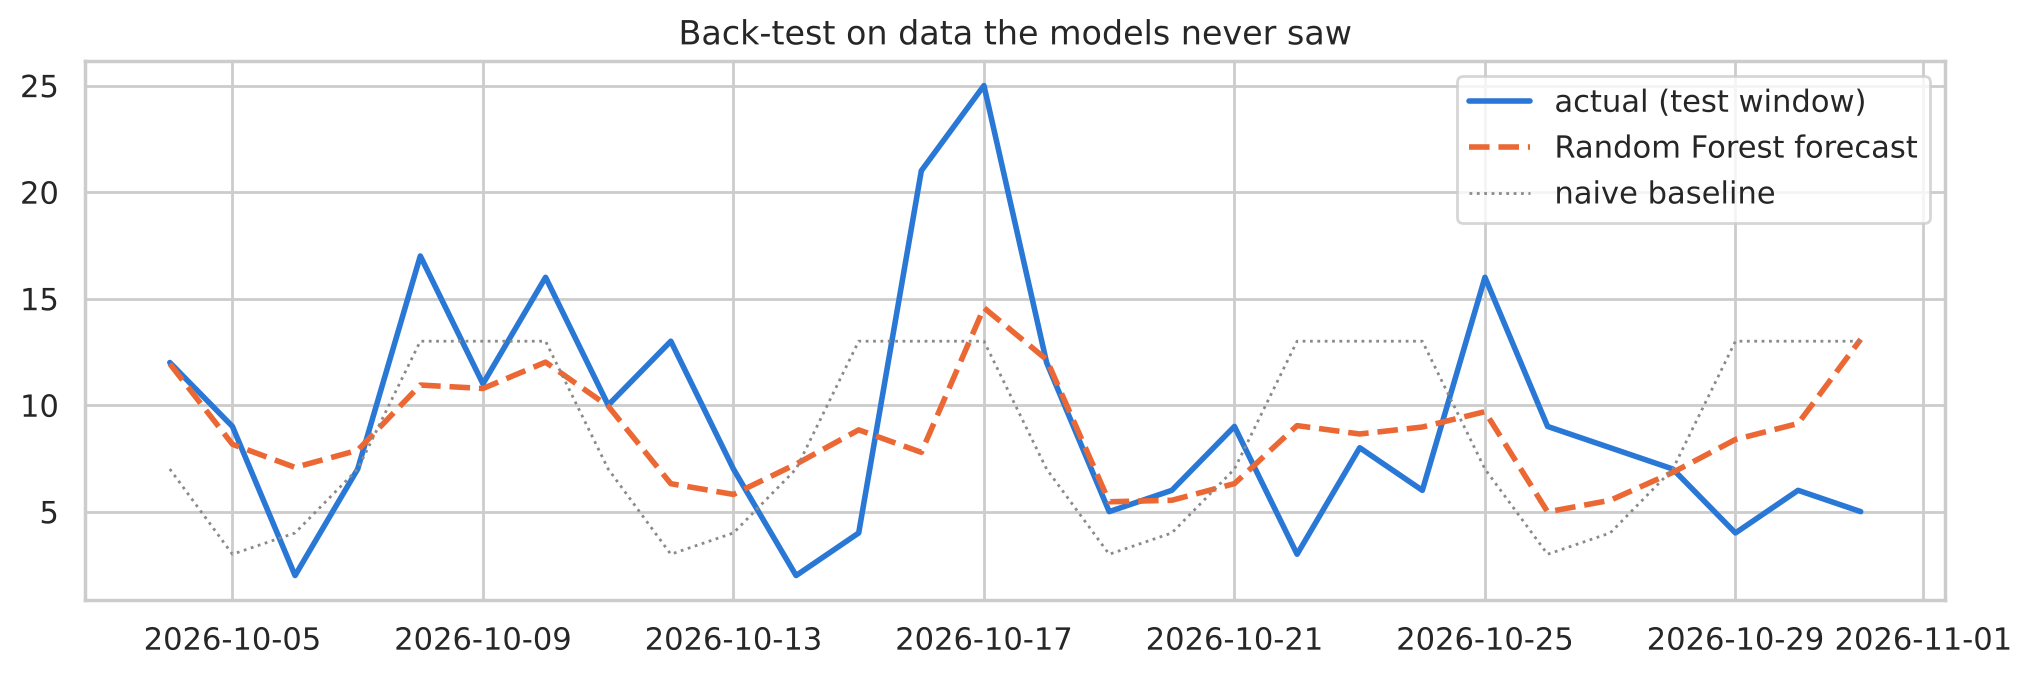

In [9]:
best = results.iloc[0].model
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(y_test.index, y_test.values, color="#2a78d6", lw=2, label="actual (test window)")
ax.plot(y_test.index, preds[best], color="#eb6834", lw=2, ls="--", label=f"{best} forecast")
ax.plot(y_test.index, preds["Naive (same day last week)"], color="#8a8a8a", lw=1, ls=":", label="naive baseline")
ax.legend(); ax.set_title("Back-test on data the models never saw"); plt.show()

## 6. Why does the model predict what it predicts? (SHAP)

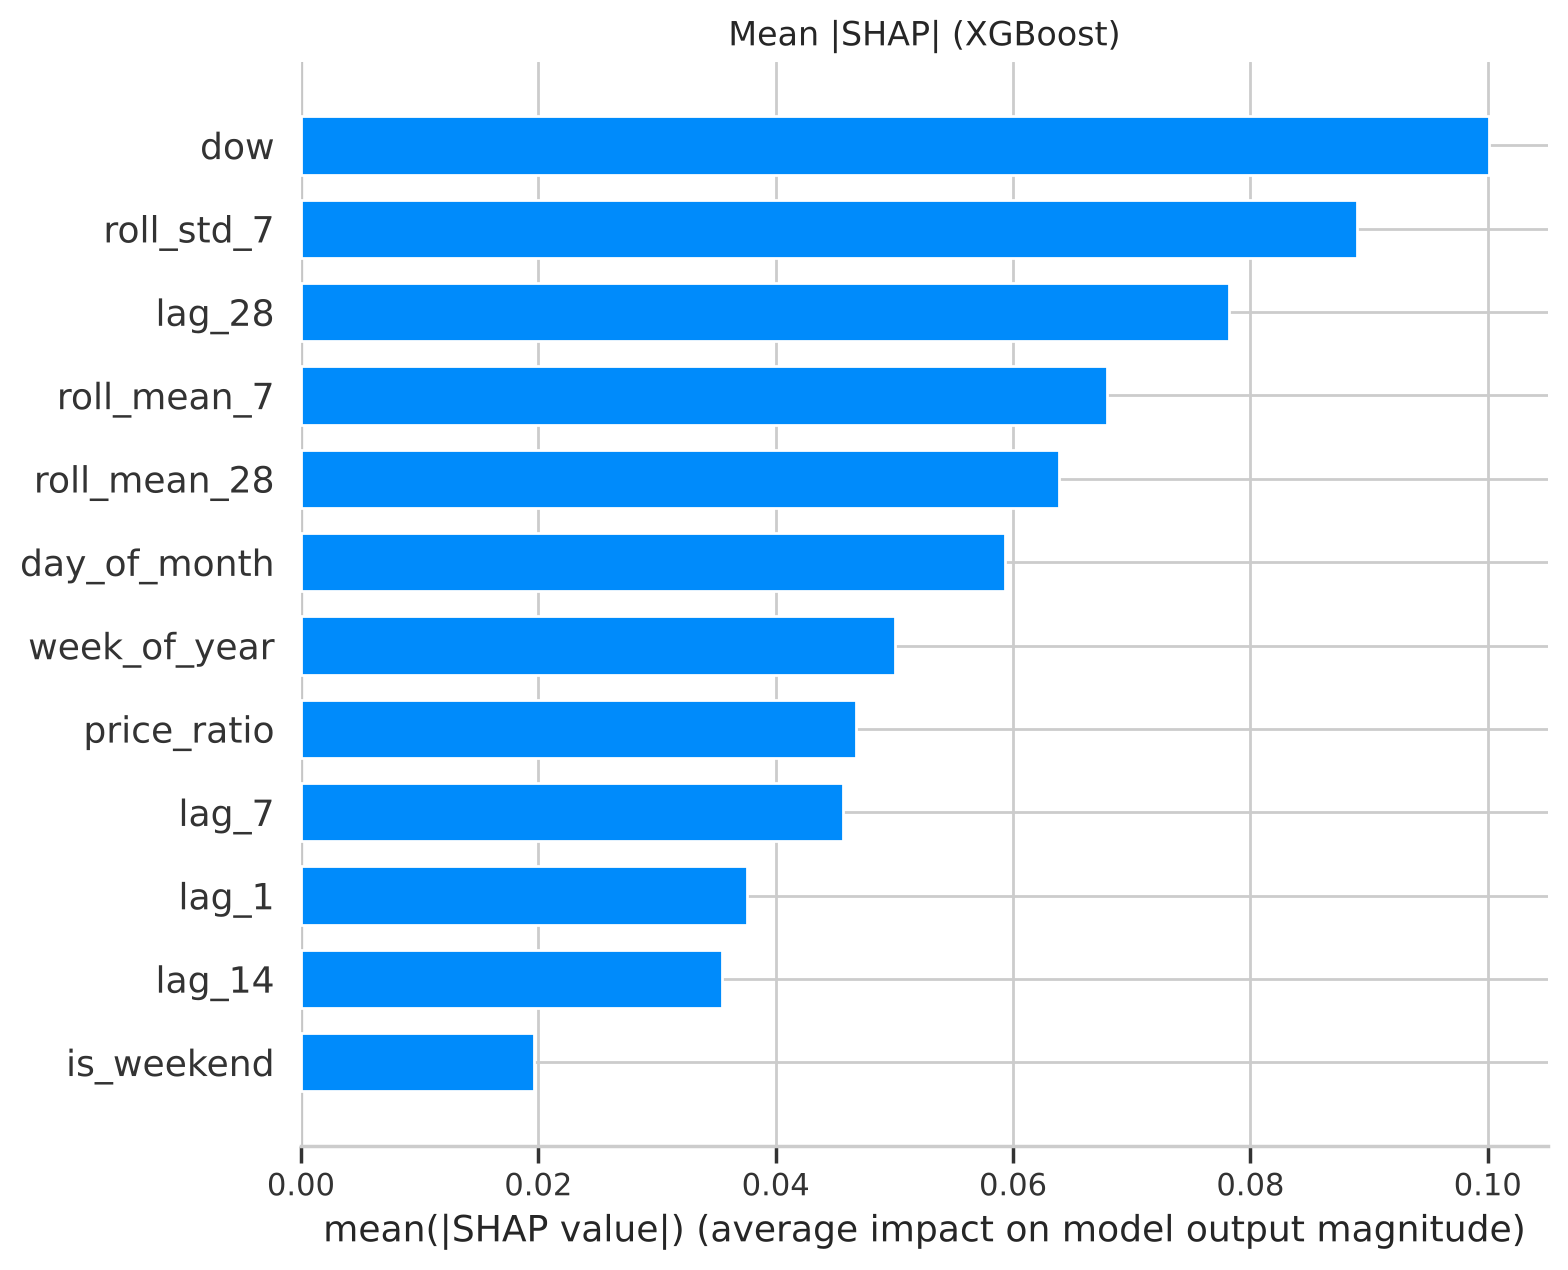

In [10]:
import shap
from app.forecasting.models import XGBoostModel
xgb = XGBoostModel().fit(y, cal)
X = xgb.X_train.tail(300)
sv = shap.TreeExplainer(xgb.model).shap_values(X.to_numpy())
shap.summary_plot(sv, X, plot_type="bar", show=False, max_display=12); plt.title("Mean |SHAP| (XGBoost)"); plt.show()

## 7. From forecast to inventory decision
The app's optimiser uses textbook formulas: safety stock = z·σ·√L, reorder point = lead-time demand + safety stock.

In [11]:
from app.inventory.optimizer import compute_position
recent = y.iloc[-56:]
item_cfg = {"lead_time_days": 3, "review_period_days": 7, "service_level": 0.95, "on_hand": 40, "min_order_qty": 1,
            "pack_size": 6, "unit_cost": 2.3, "order_cost": 25, "holding_cost_rate": 0.25, "replenishment_policy": "order_up_to",
            "product_name": "Whole Milk"}
future = XGBoostModel().fit(y, cal).predict(10, cal.iloc[-10:].set_index(pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=10)))
pos = compute_position(item_cfg, recent.mean(), recent.std(), list(future), overstock_days=60)
pd.Series(pos)

avg_daily_demand                                                          9.29
demand_std                                                                 6.0
demand_source                                                         forecast
expected_demand_lead_time                                                 20.2
expected_demand_cycle                                                     59.7
safety_stock                                                              17.1
reorder_point                                                             37.3
recommended_stock_level                                                   76.8
recommended_order_qty                                                        0
eoq                                                                      435.4
days_of_inventory                                                          6.7
stockout_risk_pct                                                          2.8
status                                              

## Key takeaways

* Retail demand is noisy and **intermittent**: WAPE is more reliable than MAPE when there are zero-sales days.
* Always compare ML models against **naive baselines**. Sometimes the simple model wins, and the app reports that honestly.
* SHAP shows **association learned by the model**, not cause and effect.
* All results above come from **synthetic** demonstration data.